# 03 Focusing in 3D

**Series:** Physics of the Integratron (Landers, California)
**Topic T3:** how much stronger the hot spot is when the whole dome focuses, not just a slice of it, and what shape it takes.

Notebook 01 worked in a vertical slice through the centre. That slice behaves like a long curved wall, a cylinder, which focuses sound in only one direction. The real dome curves in every direction, so it focuses sound from all sides at once. This notebook repeats the focusing calculation over the full dome.

1. **The whole wall.** The wave sum from notebook 01, extended over a sphere, and a check that it gives the right answer for a flat wall.
2. **The hot spot as a blob.** Maps of the hot spot seen from above and from the side.
3. **How much louder.** The gain at the mirror point and at the centre, in 3D and in the 2D slice.
4. **How big.** The size of the hot spot in each direction, compared with a human head.

In [9]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider

SPEED_OF_SOUND = 343.0                   # m/s, air at 20 °C
DOME_RADIUS = 55 * 0.3048 / 2            # 55 ft diameter -> 8.38 m
R = DOME_RADIUS

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

## 1. Summing over the whole wall

Notebook 01 added up a small wave from every patch of wall. In 3D each patch of area $dA$ is treated the same way: it is hit by the wave from the source and re-radiates it toward the listener. The reflected pressure at the listener is

$$p_\text{refl} = \frac{k}{2\pi i} \sum_\text{patches} \underbrace{\frac{\cos\theta_\text{in} + \cos\theta_\text{out}}{2}}_{\text{obliquity}} \; \frac{e^{\,ik(r_1 + r_2)}}{r_1\, r_2}\; dA$$

where $r_1$ is the distance from the source to the patch, $r_2$ from the patch to the listener, and $k = 2\pi f/c$. The direct sound is $e^{ikr}/r$, so it falls off as $1/r$, faster than the $1/\sqrt{r}$ of the 2D slice.

The factor $k/2\pi i$ is what makes a flat wall behave like a mirror. Summing over a large flat wall must give exactly the sound of an **image source** behind the wall, $e^{ikr'}/r'$, where $r'$ is the distance from the mirror image of the source. The cell below checks this with a 30 m square wall, a source 2 m in front of it and a line of listeners.

As in notebook 01, the floor mirrors the dome, so the room acts as a full sphere. The sphere is sampled with evenly spread points, about three per wavelength.

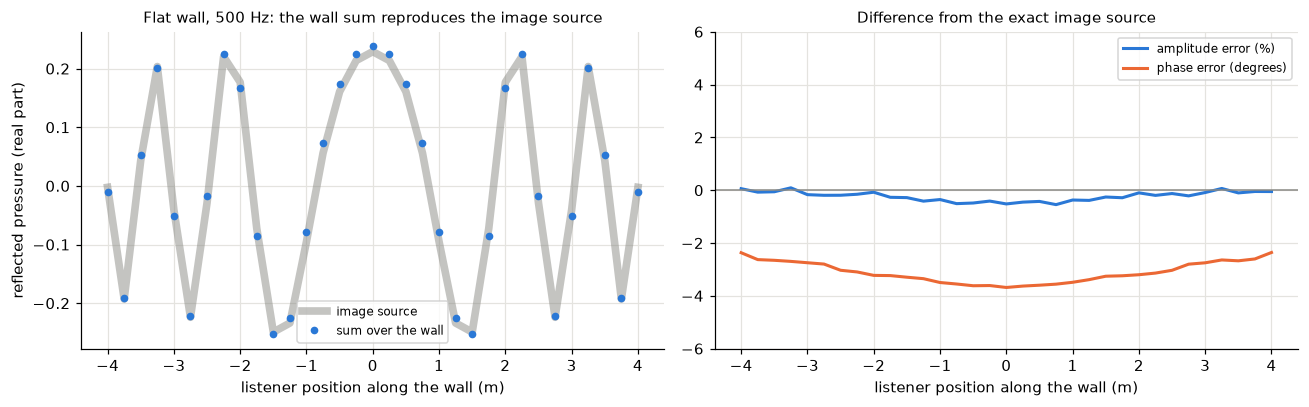

In [10]:
def kirchhoff_terms(source, receivers, points, inward, area, k):
    # Wave from each wall patch to each receiver: shape (n_receivers, n_points)
    to_wall = points - source
    r1 = np.linalg.norm(to_wall, axis=1)
    from_wall = receivers[:, None, :] - points
    r2 = np.linalg.norm(from_wall, axis=2)
    cos_in = -np.sum(to_wall * inward, axis=1) / r1
    cos_out = np.sum(from_wall * inward, axis=2) / r2
    obliquity = (cos_in + cos_out) / 2
    return obliquity * area * k / (2j * np.pi) * np.exp(1j * k * (r1 + r2)) / (r1 * r2)


# Flat wall check: a 30 m square in the plane z = 0, source 2 m in front of it
freq_hz = 500
k = 2 * np.pi * freq_hz / SPEED_OF_SOUND
spacing = SPEED_OF_SOUND / freq_hz / 5
grid = np.arange(-15, 15, spacing) + spacing / 2
PX, PY = np.meshgrid(grid, grid)
plate = np.column_stack([PX.ravel(), PY.ravel(), np.zeros(PX.size)])
plate_normal = np.tile([0.0, 0.0, 1.0], (len(plate), 1))
source = np.array([0.0, 0.0, 2.0])
listeners = np.column_stack([np.linspace(-4, 4, 33), np.zeros(33), np.full(33, 1.5)])

summed = np.array([kirchhoff_terms(source, listeners[i:i + 1], plate, plate_normal,
                                   spacing ** 2, k).sum() for i in range(len(listeners))])
r_image = np.linalg.norm(listeners - np.array([0.0, 0.0, -2.0]), axis=1)
image = np.exp(1j * k * r_image) / r_image

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.plot(listeners[:, 0], image.real, color=GREY, linewidth=5, alpha=0.5,
         label="image source")
ax1.plot(listeners[:, 0], summed.real, "o", color=BLUE, markersize=4,
         label="sum over the wall")
ax1.set_xlabel("listener position along the wall (m)")
ax1.set_ylabel("reflected pressure (real part)")
ax1.set_title(f"Flat wall, {freq_hz} Hz: the wall sum reproduces the image source",
              fontsize=10)
ax1.legend(fontsize=8)
ax2.plot(listeners[:, 0], 100 * (np.abs(summed) / np.abs(image) - 1), color=BLUE,
         label="amplitude error (%)")
ax2.plot(listeners[:, 0], np.degrees(np.angle(summed / image)), color=ORANGE,
         label="phase error (degrees)")
ax2.axhline(0, color=GREY, linewidth=1)
ax2.set_ylim(-6, 6)
ax2.set_xlabel("listener position along the wall (m)")
ax2.set_title("Difference from the exact image source", fontsize=10)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What the plots show**

- **Left:** the reflected pressure along a line of listeners 1.5 m in front of the wall. The thick grey line is the exact sound of the image source. The blue dots are the sum over 48,000 patches of wall. The dots sit on the line everywhere, through every peak and trough.
- **Right:** the difference. The amplitude is within 0.5% (blue). The phase lags by 2.4° to 3.7° (orange). That small lag comes from the formula keeping only the far-field part of each patch's wave, which is accurate when the patch is many wavelengths from the listener. Here the listeners are only about two wavelengths from the wall. In the dome they are about twelve wavelengths away at 500 Hz, and the lag drops below 1°.

The normalisation is right, so the same sum can be trusted over the sphere.

### The sphere

The function below does the same sum over the dome. It uses the fact that every wall point is exactly $R$ from the centre to compute all the distances at once, which makes the maps in this notebook fast enough to use with sliders.

When the source and the listeners are all on the floor, each patch of the real dome has a mirror twin below the floor at exactly the same distances. Only the real dome is summed and each patch counts twice.

The 2D slice model from notebook 01 is included for comparison.

In [11]:
def fibonacci_sphere(n):
    # n points spread evenly over the sphere of radius R
    i = np.arange(n) + 0.5
    z = 1 - 2 * i / n
    azimuth = np.pi * (1 + 5 ** 0.5) * i
    rho = np.sqrt(1 - z ** 2)
    return R * np.column_stack([rho * np.cos(azimuth), rho * np.sin(azimuth), z])


def sphere_reflection(source, receivers, freq_hz, on_floor=False, chunk=256):
    # First reflection from the full sphere at each receiver (z up, floor at z = 0).
    # on_floor=True: source and receivers are on the floor, so sum the real dome twice.
    k = 2 * np.pi * freq_hz / SPEED_OF_SOUND
    spacing = SPEED_OF_SOUND / freq_hz / 3
    n = max(int(4 * np.pi * R ** 2 / spacing ** 2), 4000)
    wall = fibonacci_sphere(n)
    area = np.full(n, 4 * np.pi * R ** 2 / n)
    if on_floor:
        keep = wall[:, 2] > 0
        wall, area = wall[keep], 2 * area[keep]
    to_wall = wall - source
    r1 = np.linalg.norm(to_wall, axis=1)
    cos_in = np.sum(to_wall * wall, axis=1) / (R * r1)
    weight = area * k / (2j * np.pi) / r1
    receivers = np.atleast_2d(receivers)
    field = np.empty(len(receivers), dtype=complex)
    for start in range(0, len(receivers), chunk):
        x = receivers[start:start + chunk]
        x_dot_w = x @ wall.T
        r2 = np.sqrt(np.maximum(np.sum(x ** 2, axis=1)[:, None] + R ** 2 - 2 * x_dot_w,
                                1e-12))
        cos_out = (R ** 2 - x_dot_w) / (R * r2)
        terms = (cos_in + cos_out) / 2 * weight * np.exp(1j * k * (r1 + r2)) / r2
        field[start:start + chunk] = terms.sum(axis=1)
    return field


def circle_reflection(source, receivers, freq_hz, n_wall=2400):
    # The 2D slice model from notebook 01: points are (x, height)
    k = 2 * np.pi * freq_hz / SPEED_OF_SOUND
    angle = (np.arange(n_wall) + 0.5) * 2 * np.pi / n_wall
    wall = R * np.column_stack([np.cos(angle), np.sin(angle)])
    inward = -wall / R
    to_wall = wall - source
    r1 = np.linalg.norm(to_wall, axis=1)
    from_wall = np.atleast_2d(receivers)[:, None, :] - wall
    r2 = np.linalg.norm(from_wall, axis=2)
    cos_in = np.sum(to_wall * -inward, axis=1) / r1
    cos_out = np.sum(from_wall * inward, axis=2) / r2
    amplitude = ((cos_in + cos_out) / 2 * (2 * np.pi * R / n_wall)
                 * np.sqrt(k / (2 * np.pi)) / np.sqrt(r1 * r2))
    return (amplitude * np.exp(1j * (k * (r1 + r2) - np.pi / 4))).sum(axis=1)


def half_max_width(x, intensity, centre, search):
    # Width at half height of the peak found within `search` of `centre`
    window = np.abs(x - centre) <= search
    peak = np.flatnonzero(window)[np.argmax(intensity[window])]
    above = intensity >= intensity[peak] / 2
    left = peak
    while left > 0 and above[left - 1]:
        left -= 1
    right = peak
    while right < len(x) - 1 and above[right + 1]:
        right += 1
    return x[right] - x[left]

### Which parts of the wall arrive in step

The same picture as section 3 of notebook 01, now over the whole sphere. Each dot is a patch of wall, coloured by the phase its reflection has when it reaches the listener. The source is on the floor 1 m from the centre and the note is 500 Hz. The lower half of each sphere is the floor's mirror image of the dome.

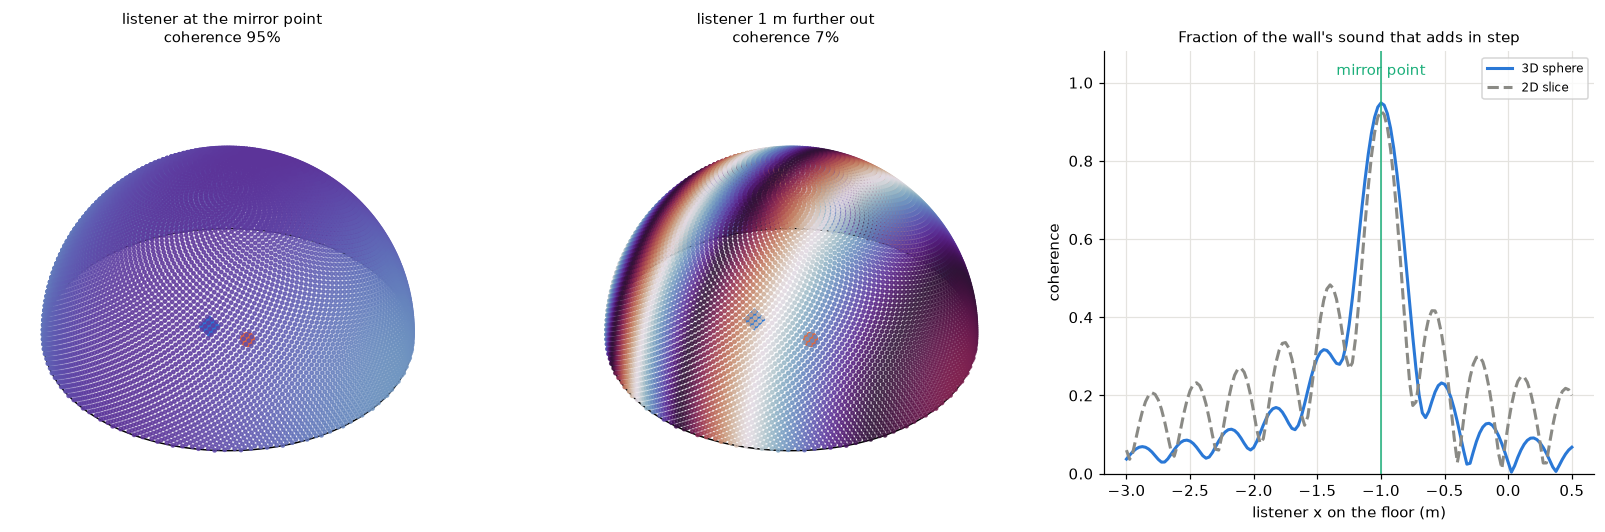

In [12]:
def wall_phase_and_coherence(source, listener, freq_hz, n=20000):
    k = 2 * np.pi * freq_hz / SPEED_OF_SOUND
    wall = fibonacci_sphere(n)
    terms = kirchhoff_terms(source, listener[None, :], wall, -wall / R,
                            4 * np.pi * R ** 2 / n, k)[0]
    return wall, np.mod(np.angle(terms), 2 * np.pi), np.abs(terms.sum()) / np.abs(terms).sum()


source = np.array([1.0, 0.0, 0.0])
fig = plt.figure(figsize=(15, 4.8))
for col, (listener_x, label) in enumerate([(-1.0, "listener at the mirror point"),
                                           (-2.0, "listener 1 m further out")]):
    wall, phase, coherence = wall_phase_and_coherence(source, np.array([listener_x, 0, 0]), 500)
    ax = fig.add_subplot(1, 3, col + 1, projection="3d")
    dome = wall[:, 2] > 0  # show the real dome only
    ax.scatter(*wall[dome].T, c=phase[dome], cmap="twilight", vmin=0, vmax=2 * np.pi,
               s=5, alpha=0.8, depthshade=False)
    rim = np.linspace(0, 2 * np.pi, 200)
    ax.plot(R * np.cos(rim), R * np.sin(rim), 0 * rim, color="k", linewidth=1)
    ax.scatter(*source, s=80, color=ORANGE, depthshade=False)
    ax.scatter(listener_x, 0, 0, s=90, marker="D", color=BLUE, depthshade=False)
    ax.set_xlim(-R, R)
    ax.set_ylim(-R, R)
    ax.set_zlim(0, R)
    ax.set_box_aspect((2, 2, 1), zoom=1.3)
    ax.view_init(elev=35, azim=-60)
    ax.set_axis_off()
    ax.set_title(f"{label}\ncoherence {coherence:.0%}", fontsize=10)

ax = fig.add_subplot(1, 3, 3)
listeners = np.linspace(-3.0, 0.5, 141)
coherence_3d = [wall_phase_and_coherence(source, np.array([x, 0, 0]), 500, n=8000)[2]
                for x in listeners]
k = 2 * np.pi * 500 / SPEED_OF_SOUND
angle = (np.arange(2400) + 0.5) * 2 * np.pi / 2400
ring = R * np.column_stack([np.cos(angle), np.sin(angle)])
coherence_2d = []
for x in listeners:
    r1 = np.linalg.norm(ring - source[[0, 2]], axis=1)
    r2 = np.linalg.norm(ring - np.array([x, 0.0]), axis=1)
    terms = np.exp(1j * k * (r1 + r2)) / np.sqrt(r1 * r2)
    coherence_2d.append(np.abs(terms.sum()) / np.abs(terms).sum())
ax.plot(listeners, coherence_3d, color=BLUE, label="3D sphere")
ax.plot(listeners, coherence_2d, color=GREY, linestyle="--", label="2D slice")
ax.axvline(-1.0, color=AQUA, linewidth=1)
ax.text(-1.0, 1.02, "mirror point", color=AQUA, ha="center")
ax.set_ylim(0, 1.08)
ax.set_xlabel("listener x on the floor (m)")
ax.set_ylabel("coherence")
ax.set_title("Fraction of the wall's sound that adds in step", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**What the plots show** (source 1 m from the centre, 500 Hz)

- **Left:** with the listener at the mirror point, the whole dome is nearly one shade of purple. Reflections from every direction, including the top of the dome and all the way around the sides, arrive in step. Coherence is 95%.
- **Middle:** with the listener 1 m further out, the dome breaks into broad colour bands. The reflections arrive with every phase and mostly cancel. Coherence drops to 7%.
- **Right:** coherence for a listener moving along the floor. Both models peak at the mirror point, the 3D sphere at 95% and the 2D slice at 93%. Away from the peak they differ. The 2D slice keeps strong side peaks of 20% to 48%. In 3D the side peaks are lower, and at 1 m out the 3D coherence is 7% against 16% for the 2D slice.

Coherence is almost the same at the focus in 2D and 3D. The difference is how much wall takes part. The 2D slice adds up one ring of wall. The 3D sum adds up the whole area of the dome, so the total is far larger. Section 3 measures how much.

## 2. The hot spot as a blob

The sliders set the source's distance from the centre and the frequency. The plots zoom in on the mirror point.

- **Left:** the floor seen from above. Loudness of the reflected sound in dB below its peak.
- **Middle:** a vertical slice through the mirror point, seen from the side, computed separately over the full sphere.
- **Right:** loudness along lines through the peak, along the floor toward the source (x), across the floor (y), and the same lines in the 2D slice model.

The black circle is 20 cm across, about the size of a head. Only the reflected sound is shown. The direct sound from the source is left out so it does not swamp the picture.

Each update takes one to three seconds. The frequency stops at 800 Hz to keep it that way. Section 4 goes up to 1000 Hz.

In [13]:
@interact(
    offset_m=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.25,
                         description="source d (m)", continuous_update=False,
                         style=SLIDER_STYLE),
    freq_hz=FloatSlider(value=500, min=125, max=800, step=25,
                        description="freq (Hz)", continuous_update=False,
                        style=SLIDER_STYLE),
)
def show_hot_spot(offset_m, freq_hz):
    wavelength = SPEED_OF_SOUND / freq_hz
    half = min(1.5 * wavelength, 3.0)
    source = np.array([offset_m, 0.0, 0.0])
    xs = np.linspace(-offset_m - half, -offset_m + half, 51)
    hs = np.linspace(0, half, 26)
    X, H = np.meshgrid(xs, hs)
    zeros = np.zeros(X.size)

    top = np.abs(sphere_reflection(source, np.column_stack([X.ravel(), H.ravel(), zeros]),
                                   freq_hz, on_floor=True)).reshape(X.shape) ** 2
    side = np.abs(sphere_reflection(source, np.column_stack([X.ravel(), zeros, H.ravel()]),
                                    freq_hz)).reshape(X.shape) ** 2
    peak = top.max()
    top_db = 10 * np.log10(top / peak)
    side_db = 10 * np.log10(side / peak)
    top_full = np.vstack([top_db[::-1], top_db[1:]])  # mirror y to show both sides

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5), layout="constrained",
                                        gridspec_kw={"width_ratios": [1, 1, 1.1]})
    ax1.imshow(top_full, origin="lower", extent=[xs[0], xs[-1], -half, half],
               cmap="magma", vmin=-20, vmax=0)
    im = ax2.imshow(side_db, origin="lower", extent=[xs[0], xs[-1], 0, half],
                    cmap="magma", vmin=-20, vmax=0)
    head = np.linspace(0, 2 * np.pi, 100)
    ax1.plot(-offset_m + 0.1 * np.cos(head), 0.1 * np.sin(head), color="k", linewidth=1)
    ax2.plot(-offset_m + 0.1 * np.cos(head), 0.1 + 0.1 * np.sin(head), color="k",
             linewidth=1)
    ax1.set_xlabel("x (m)")
    ax1.set_ylabel("y across the floor (m)")
    ax1.set_title("Floor from above", fontsize=10)
    ax2.set_xlabel("x (m)")
    ax2.set_ylabel("height above floor (m)")
    ax2.set_title("Side view through the mirror point", fontsize=10)
    for ax in (ax1, ax2):
        ax.set_aspect("equal")
        ax.grid(False)
    fig.colorbar(im, ax=ax2, location="bottom", shrink=0.8, label="dB below peak")
    fig.suptitle(f"Source {offset_m:.2f} m from the centre, mirror point at x = {-offset_m:.2f} m")

    along = top[0] / top[0].max()
    j = np.argmin(np.abs(xs + offset_m))
    across = top[:, j] / top[:, j].max()
    slice_2d = np.abs(circle_reflection(source[[0, 2]],
                                        np.column_stack([xs, np.zeros_like(xs)]),
                                        freq_hz)) ** 2
    ax3.plot(xs + offset_m, along, color=BLUE, label="3D, along x")
    ax3.plot(np.concatenate([-hs[::-1], hs[1:]]),
             np.concatenate([across[::-1], across[1:]]), color=ORANGE, label="3D, across (y)")
    ax3.plot(xs + offset_m, slice_2d / slice_2d.max(), color=GREY, linestyle="--",
             label="2D slice, along x")
    ax3.axhline(1.0, color=GREY, linestyle=":", label="2D slice, across (no change)")
    ax3.set_xlim(-half, half)
    ax3.set_ylim(0, 1.15)
    ax3.set_xlabel("distance from the mirror point (m)")
    ax3.set_ylabel("loudness (peak = 1)")
    ax3.set_title(f"Profiles at {freq_hz:.0f} Hz (λ = {wavelength:.2f} m)", fontsize=10)
    ax3.legend(fontsize=7, loc="upper right")
    plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='source d (m)', max=3.0, ste…

**What the plots show** (defaults: source at 1 m, 500 Hz)

- **Left:** the floor from above. A round bright blob sits on the mirror point, a little wider than the 20 cm head circle. It is ringed by faint circles about 10 dB down. Unlike the 2D model, where the hot spot ran on forever out of the slice, this one has a limit in every direction.
- **Middle:** the side view, computed separately over the full sphere. It is the top half of the left-hand map. That is not a coincidence. The sphere looks the same from every direction around the line through the source and the centre, so the hot spot does too, and its height equals its width.
- **Right:** the blue (along x) and orange (across) profiles lie on top of each other, both about 0.3 m wide at half height. The grey dashed 2D profile is a little narrower but has side peaks up to 0.27, more than twice the 3D ones. The dotted line at 1 shows the 2D model across the floor: it never drops at all.

**Try this:**

- Set $d = 0$. The hot spot becomes a perfect target on the centre: a round blob with rings. The first ring is at 5% of the peak in 3D, against 16% in the 2D slice.
- Set $d = 2$ m. The blob stretches into a streak along the x axis, a line of sound pointing at the source. The loudest point moves 0.33 m toward the centre to x = −1.67 m, as the 2D model found in notebook 01. Across the floor the streak stays narrow, 0.26 m at half height.
- Set $d = 3$ m. The streak is longer and its loudest point is at x = −2.29 m, 0.7 m from the mirror point.
- Raise the frequency to 800 Hz with $d = 1$ m. The blob shrinks to about the size of the head circle and four faint dark spots appear around it, where the first ring starts to break up.

## 3. How much louder

The **gain** at a point is how much louder the reflected sound is there than the direct sound arriving at the same point, in dB.

For a source at the centre there is a clean answer. Every path is $2R$ and every patch of wall arrives in step. The sum becomes

$$|p_\text{refl}| = \frac{k}{2\pi} \cdot \frac{4\pi R^2}{R \cdot R} = 2k \quad \text{(3D)} \qquad\qquad |p_\text{refl}| = \sqrt{\frac{k}{2\pi}} \cdot \frac{2\pi R}{\sqrt{R \cdot R}} = \sqrt{2\pi k} \quad \text{(2D)}$$

In 3D the echo grows in proportion to the frequency, 6 dB for every doubling. In 2D it grows only as the square root, 3 dB per doubling. Neither depends on the size of the dome: a bigger dome has more wall but each patch is further away, and the two effects cancel.

For an off-centre source there is no formula, so the gain is computed at the loudest point near the mirror point.

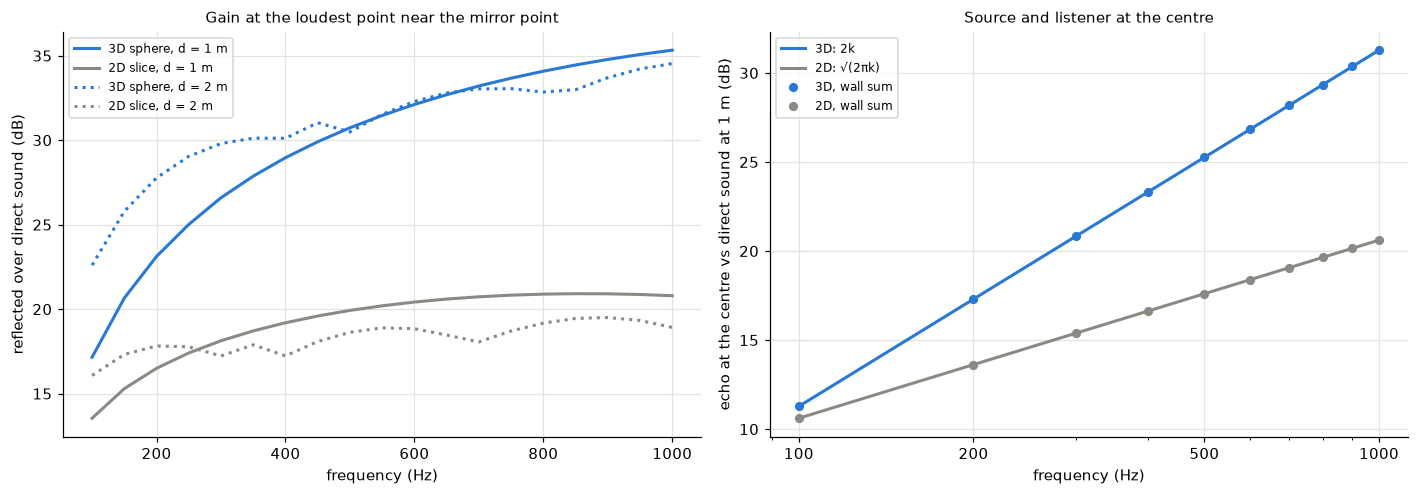

  250 Hz: d = 1 m gain 3D 25.0 dB, 2D 17.4 dB | centre echo = direct sound at 10.9 cm
  500 Hz: d = 1 m gain 3D 30.7 dB, 2D 19.9 dB | centre echo = direct sound at 5.5 cm
 1000 Hz: d = 1 m gain 3D 35.3 dB, 2D 20.8 dB | centre echo = direct sound at 2.7 cm


In [14]:
freqs = np.arange(100, 1001, 50)


def loudest_near_mirror(offset_m, freq_hz, model):
    xs = np.linspace(-offset_m - 1.0, -offset_m + 1.0, 201)
    if model == "3D":
        source = np.array([offset_m, 0.0, 0.0])
        field = sphere_reflection(source, np.column_stack([xs, 0 * xs, 0 * xs]), freq_hz,
                                  on_floor=True)
        direct = 1 / np.abs(xs - offset_m)
    else:
        source = np.array([offset_m, 0.0])
        field = circle_reflection(source, np.column_stack([xs, 0 * xs]), freq_hz)
        direct = 1 / np.sqrt(np.abs(xs - offset_m))
    i = np.argmax(np.abs(field))
    return 20 * np.log10(np.abs(field[i]) / direct[i]), xs[i]


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6))
for offset_m, style in [(1.0, "-"), (2.0, ":")]:
    gain_3d = [loudest_near_mirror(offset_m, f, "3D")[0] for f in freqs]
    gain_2d = [loudest_near_mirror(offset_m, f, "2D")[0] for f in freqs]
    ax1.plot(freqs, gain_3d, style, color=BLUE, label=f"3D sphere, d = {offset_m:.0f} m")
    ax1.plot(freqs, gain_2d, style, color=GREY, label=f"2D slice, d = {offset_m:.0f} m")
ax1.set_xlabel("frequency (Hz)")
ax1.set_ylabel("reflected over direct sound (dB)")
ax1.set_title("Gain at the loudest point near the mirror point", fontsize=10)
ax1.legend(fontsize=8)

k = 2 * np.pi * freqs / SPEED_OF_SOUND
centre = np.array([[1e-9, 0.0, 0.0]])
numeric_3d = [np.abs(sphere_reflection(np.zeros(3), centre, f)[0]) for f in freqs]
numeric_2d = [np.abs(circle_reflection(np.zeros(2), centre[:, :2], f)[0]) for f in freqs]
ax2.plot(freqs, 20 * np.log10(2 * k), color=BLUE, label="3D: 2k")
ax2.plot(freqs, 20 * np.log10(np.sqrt(2 * np.pi * k)), color=GREY, label="2D: √(2πk)")
ax2.plot(freqs[::2], 20 * np.log10(numeric_3d)[::2], "o", color=BLUE, markersize=5,
         label="3D, wall sum")
ax2.plot(freqs[::2], 20 * np.log10(numeric_2d)[::2], "o", color=GREY, markersize=5,
         label="2D, wall sum")
ax2.set_xscale("log")
ax2.set_xticks([100, 200, 500, 1000])
ax2.set_xticklabels(["100", "200", "500", "1000"])
ax2.set_xlabel("frequency (Hz)")
ax2.set_ylabel("echo at the centre vs direct sound at 1 m (dB)")
ax2.set_title("Source and listener at the centre", fontsize=10)
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

for f in (250, 500, 1000):
    print(f"{f:5d} Hz: d = 1 m gain 3D {loudest_near_mirror(1.0, f, '3D')[0]:.1f} dB, "
          f"2D {loudest_near_mirror(1.0, f, '2D')[0]:.1f} dB | "
          f"centre echo = direct sound at {100 / (2 * 2 * np.pi * f / SPEED_OF_SOUND):.1f} cm")

**What the plots show**

- **Left:** how much louder the focused reflection is than the direct sound at the same point. For $d = 1$ m (solid lines) the 3D gain rises from 17 dB at 100 Hz to 35 dB at 1000 Hz. The 2D slice rises from 14 dB to only 21 dB. At 500 Hz the 3D gain is 30.7 dB against 19.9 dB, a difference of 11 dB, or 12 times the energy. The gap grows with frequency.
- The $d = 2$ m curves (dotted) start higher. That is because their direct sound has 4 m to travel instead of 2 m, so it is weaker. Above about 700 Hz the 3D $d = 2$ m curve falls behind the $d = 1$ m curve, because its focus smears into the streak seen in section 2.
- **Right:** the echo at the centre with the source at the centre, against the direct sound 1 m away. The lines are the formulas $2k$ and $\sqrt{2\pi k}$. The dots are the full wall sums and land on the lines exactly. On this log axis the 3D line climbs 6 dB per doubling of frequency and the 2D line 3 dB.

The printed lines put the centre echo in everyday terms. At 500 Hz the first echo of your voice at the centre is as loud as your voice heard from 5.5 cm away. At 1000 Hz it matches 2.7 cm. This is one reflection from a perfectly hard wall, before any absorption.

## 4. How big

The hot spot's width at half its peak loudness, measured three ways for a source 1 m from the centre:

- **3D, along x:** along the floor, on the line through the source and the centre.
- **3D, across:** along the floor at right angles to that line. The height of the blob is the same, because of the symmetry shown in section 2.
- **2D slice:** along the floor in the model from notebook 01. Out of the slice, the 2D hot spot has no limit at all.

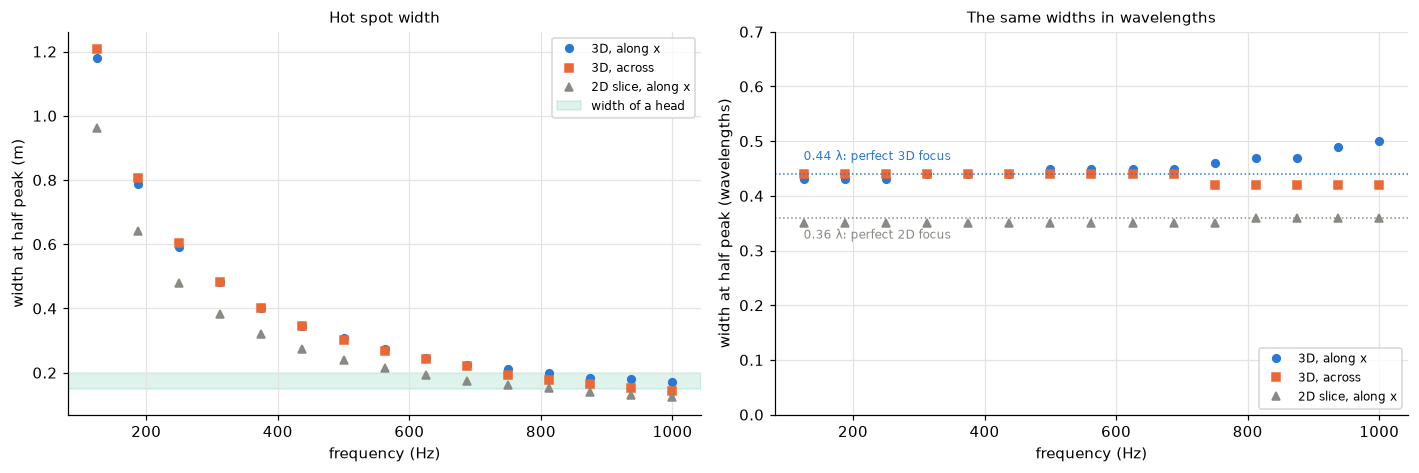

In [15]:
offset_m = 1.0
source = np.array([offset_m, 0.0, 0.0])
freqs = np.arange(125, 1001, 62.5)
widths = {"3D, along x": [], "3D, across": [], "2D slice, along x": []}
for f in freqs:
    wavelength = SPEED_OF_SOUND / f
    xs = np.linspace(-offset_m - 1.2 * wavelength, -offset_m + 1.2 * wavelength, 241)
    ys = np.linspace(-1.2 * wavelength, 1.2 * wavelength, 241)
    along = np.abs(sphere_reflection(source, np.column_stack([xs, 0 * xs, 0 * xs]), f,
                                     on_floor=True)) ** 2
    across = np.abs(sphere_reflection(source, np.column_stack([0 * ys - offset_m, ys, 0 * ys]),
                                      f, on_floor=True)) ** 2
    flat = np.abs(circle_reflection(source[[0, 2]], np.column_stack([xs, 0 * xs]), f)) ** 2
    widths["3D, along x"].append(half_max_width(xs, along, -offset_m, wavelength / 4))
    widths["3D, across"].append(half_max_width(ys, across, 0.0, wavelength / 4))
    widths["2D slice, along x"].append(half_max_width(xs, flat, -offset_m, wavelength / 4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
styles = {"3D, along x": (BLUE, "o"), "3D, across": (ORANGE, "s"),
          "2D slice, along x": (GREY, "^")}
for name, values in widths.items():
    colour, marker = styles[name]
    ax1.plot(freqs, values, marker, color=colour, markersize=5, label=name)
    ax2.plot(freqs, np.array(values) / (SPEED_OF_SOUND / freqs), marker, color=colour,
             markersize=5, label=name)
ax1.axhspan(0.15, 0.20, color=AQUA, alpha=0.15, label="width of a head")
ax1.set_xlabel("frequency (Hz)")
ax1.set_ylabel("width at half peak (m)")
ax1.set_title("Hot spot width", fontsize=10)
ax1.legend(fontsize=8)
ax2.axhline(0.44, color=BLUE, linestyle=":", linewidth=1)
ax2.text(125, 0.46, "0.44 λ: perfect 3D focus", color=BLUE, va="bottom", fontsize=8)
ax2.axhline(0.36, color=GREY, linestyle=":", linewidth=1)
ax2.text(125, 0.34, "0.36 λ: perfect 2D focus", color=GREY, va="top", fontsize=8)
ax2.set_ylim(0, 0.7)
ax2.set_xlabel("frequency (Hz)")
ax2.set_ylabel("width at half peak (wavelengths)")
ax2.set_title("The same widths in wavelengths", fontsize=10)
ax2.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**What the plots show** (source at 1 m)

- **Left:** the hot spot's width in metres. All three shrink as frequency rises. The 3D blob is 1.2 m wide at 125 Hz, 0.30 m at 500 Hz and about 0.16 m at 1000 Hz. It reaches the width of a head (green band) between 800 and 1000 Hz. The 2D slice is narrower at every frequency, 0.24 m at 500 Hz.
- **Right:** the same widths divided by the wavelength. Each set sits on its own flat line. The 3D blob is 0.44 wavelengths wide, the 2D slice 0.36. Above 750 Hz the 3D widths split slightly, 0.5 λ along x and 0.42 λ across, as the blob begins to stretch along the axis.

The 3D hot spot is about 25% **wider** than the 2D one along the floor. The two flat lines are what a perfect focus gives. A wave converging from every direction in 3D peaks as $\sin(kr)/kr$, which falls to half its loudness at 0.44 λ. A wave converging from every direction in a 2D plane peaks as a Bessel function $J_0(kr)$, which falls faster. The 2D slice was right about the width along the floor within 25%. It was wrong about the other direction, where it put no limit at all.

### The hot spot to scale

The surfaces below enclose the region within 3 dB of the peak, sitting on the floor at the mirror point, for a source 1 m from the centre. The grey wire sphere is a head 20 cm across, resting on the floor.

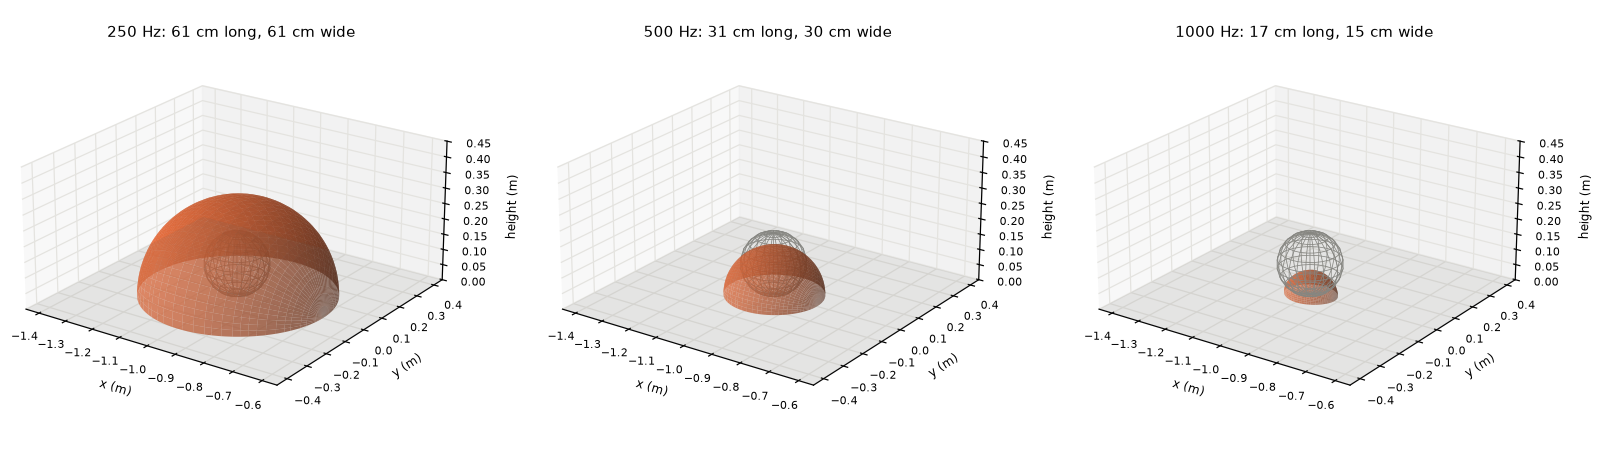

In [16]:
def hot_spot_surface(offset_m, freq_hz, level_db=-3):
    # Contour of the floor map at level_db, spun around the x axis (the map is symmetric)
    wavelength = SPEED_OF_SOUND / freq_hz
    half = 0.8 * wavelength
    xs = np.linspace(-offset_m - half, -offset_m + half, 121)
    ys = np.linspace(0, half, 61)
    X, Y = np.meshgrid(xs, ys)
    field = sphere_reflection(np.array([offset_m, 0.0, 0.0]),
                              np.column_stack([X.ravel(), Y.ravel(), 0 * X.ravel()]),
                              freq_hz, on_floor=True)
    level = 10 * np.log10(np.abs(field.reshape(X.shape)) ** 2 / np.abs(field).max() ** 2)
    contour = plt.figure().add_subplot().contour(X, Y, level, levels=[level_db])
    plt.close()
    segments = contour.allsegs[0]
    outline = min(segments, key=lambda s: np.min(np.hypot(s[:, 0] + offset_m, s[:, 1])))
    outline = outline[np.argsort(outline[:, 0])]
    spin = np.linspace(0, np.pi, 40)  # upper half only: the floor cuts the blob
    sx = np.repeat(outline[:, :1], len(spin), axis=1)
    sy = outline[:, 1:2] * np.cos(spin)
    sz = outline[:, 1:2] * np.sin(spin)
    return sx, sy, sz, np.ptp(outline[:, 0]), 2 * outline[:, 1].max()


fig = plt.figure(figsize=(15, 4.6))
u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 24), np.linspace(0, np.pi, 12))
for col, freq_hz in enumerate([250, 500, 1000]):
    sx, sy, sz, length, width = hot_spot_surface(1.0, freq_hz)
    ax = fig.add_subplot(1, 3, col + 1, projection="3d")
    ax.plot_surface(sx, sy, sz, color=ORANGE, alpha=0.75, linewidth=0)
    ax.plot_wireframe(-1.0 + 0.1 * np.cos(u) * np.sin(v), 0.1 * np.sin(u) * np.sin(v),
                      0.1 + 0.1 * np.cos(v), color=GREY, linewidth=0.5)
    span = 0.45
    floor = np.array([-1 - span, -1 + span])
    FX, FY = np.meshgrid(floor, [-span, span])
    ax.plot_surface(FX, FY, 0 * FX, color=GREY, alpha=0.12)
    ax.set_xlim(-1 - span, -1 + span)
    ax.set_ylim(-span, span)
    ax.set_zlim(0, span)
    ax.set_box_aspect((2, 2, 1))
    ax.view_init(elev=22, azim=-55)
    ax.set_xlabel("x (m)", fontsize=8)
    ax.set_ylabel("y (m)", fontsize=8)
    ax.set_zlabel("height (m)", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.set_title(f"{freq_hz} Hz: {100 * length:.0f} cm long, {100 * width:.0f} cm wide",
                 fontsize=10, y=1.0)
fig.subplots_adjust(left=0.02, right=0.98, top=0.92, bottom=0.05, wspace=0.05)
plt.show()

**What the figure shows**

- **250 Hz:** the hot spot is a dome 61 cm across that swallows the head completely. Anyone lying with their head near the mirror point is inside it.
- **500 Hz:** 31 cm long and 30 cm wide, still larger than the head.
- **1000 Hz:** 17 cm long and 15 cm wide, smaller than the head. Moving 10 cm takes an ear out of it. Each ear can hear a different loudness.

Each blob is half of a sphere because the floor cuts it. In the full sphere model it would be a round ball centred on the floor.

## Summary

| Idea | Formula | Integratron scale |
|---|---|---|
| Wall sum in 3D | $\frac{k}{2\pi i}\sum \text{obliquity}\,\frac{e^{ik(r_1+r_2)}}{r_1 r_2}\,dA$ | flat-wall check within 0.5% |
| Coherence at the mirror point | $\lvert\sum\rvert / \sum\lvert\cdot\rvert$ | 95% in 3D, 93% in 2D at 500 Hz |
| Centre echo | $2k$ (3D), $\sqrt{2\pi k}$ (2D) | 25 dB vs 18 dB at 500 Hz, re direct at 1 m |
| Gain at the mirror point | reflected / direct | 31 dB (3D) vs 20 dB (2D) at 500 Hz, $d$ = 1 m |
| Hot spot width | $0.44\,\lambda$ (3D), $0.36\,\lambda$ (2D) | 30 cm at 500 Hz, 16 cm at 1 kHz |

1. Summing over the whole dome uses the same wave sum as the 2D slice, with a $k/2\pi i$ factor that makes a flat wall act as a mirror.
2. At the mirror point nearly all of the dome arrives in step, the same fraction as in the 2D slice. But the whole dome takes part, not one ring of it.
3. That makes the 3D focus about 11 dB stronger than the 2D slice at 500 Hz, and the gap grows with frequency. At the centre the echo grows 6 dB per doubling of frequency.
4. The hot spot is a round blob, equally wide along the floor, across it and upward, 0.44 wavelengths across. At 1 kHz it is smaller than a head.
5. Further from the centre the blob stretches into a streak along the line toward the source, and its loudest point moves inward.

**Next:** [04 Whispering Gallery](04_whispering_gallery.ipynb): why a whisper close to the wall clings to it and travels all the way around the room.